In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
#TASK 01

# Loading the dataset and adding the headers
url = 'https://raw.githubusercontent.com/kumudlakara/Medium-codes/main/linear_regression/house_price_data.txt'
df = pd.read_csv(url, sep=",", header=None, names=["Size", "Bedroom", "Price"])

# Displaying the dataframe
df.head()


,Size,Bedroom,Price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


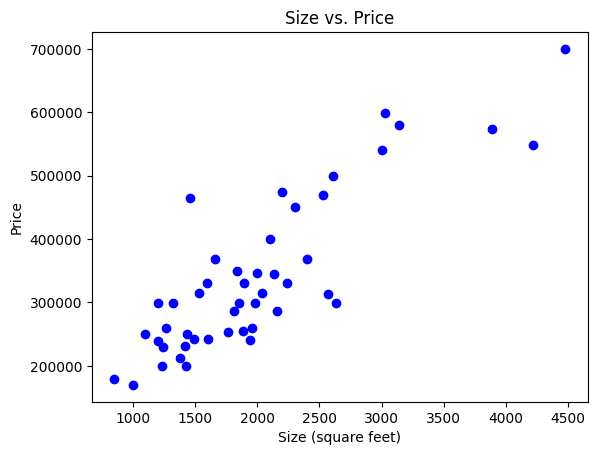

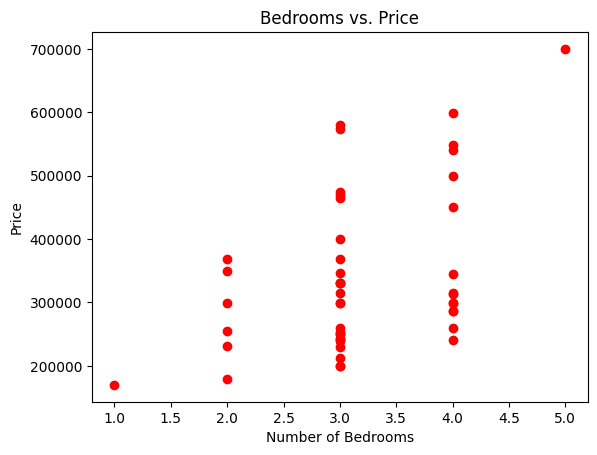

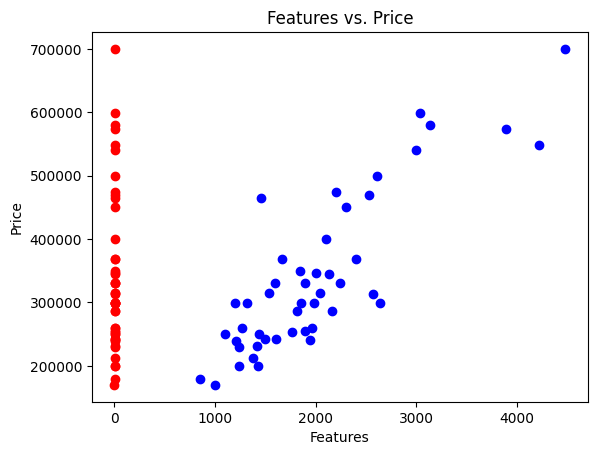

In [5]:
#TASK 02

#Let us plot Size vs. Price

plt.scatter(df['Size'], df['Price'], color='blue', label='Size')
plt.xlabel('Size (square feet)')
plt.ylabel('Price')
plt.title('Size vs. Price')
plt.show()

#Let us plot Bedroom vs. Price

plt.scatter(df['Bedroom'], df['Price'], color='red', label='Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.title('Bedrooms vs. Price')
plt.show()

#Let us plot Size and Bedroom vs. Price

plt.scatter(df['Size'], df['Price'], color='blue', label='Size')
plt.scatter(df['Bedroom'], df['Price'], color='red', label='Bedrooms')
plt.xlabel('Features')
plt.ylabel('Price')
plt.title('Features vs. Price')
plt.show()

In [6]:
#Task 03
#Let us display statistical information
print(df.describe())
#Let us display the variance also
print(df.var())

              Size    Bedroom          Price
count    47.000000  47.000000      47.000000
mean   2000.680851   3.170213  340412.659574
std     794.702354   0.760982  125039.899586
min     852.000000   1.000000  169900.000000
25%    1432.000000   3.000000  249900.000000
50%    1888.000000   3.000000  299900.000000
75%    2269.000000   4.000000  384450.000000
max    4478.000000   5.000000  699900.000000
Size       6.315518e+05
Bedroom    5.790934e-01
Price      1.563498e+10
dtype: float64


In [7]:
#Task 04

from sklearn.preprocessing import MinMaxScaler

# Let us prepare the dataset by Min-Max Normalization
scaler_min_max = MinMaxScaler()
df_min_max = pd.DataFrame(scaler_min_max.fit_transform(df), columns=df.columns)

# Let us display the normalized data
print("Min-Max Normalization:\n", df_min_max.head())


Min-Max Normalization:
        Size  Bedroom     Price
0  0.345284     0.50  0.433962
1  0.206288     0.50  0.301887
2  0.426917     0.50  0.375660
3  0.155543     0.25  0.117170
4  0.592388     0.75  0.698113


In [8]:
#Task 05
import pandas as pd
from sklearn.model_selection import train_test_split

# X will contain the input features: 'Size' and 'Bedrooms'
# y will contain the output feature: 'Price'
X = df[['Size', 'Bedroom']]
y = df['Price']

# Let us split the dataset into training and testing sets
# The test set will be 20% of the dataset (test_size=0.2)
# random_state=42 ensures the split is reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Let us display the first five rows of the training and testing sets to ensure they split correctly
print("First five rows of the training set (X_train):")
print(X_train.head(), "\n")

print("First five rows of the training target (y_train):")
print(y_train.head(), "\n")

print("First five rows of the testing set (X_test):")
print(X_test.head(), "\n")

print("First five rows of the testing target (y_test):")
print(y_test.head())


First five rows of the training set (X_train):
    Size  Bedroom
8   1380        3
3   1416        2
6   1534        3
40  1664        2
33  3137        3 

First five rows of the training target (y_train):
8     212000
3     232000
6     314900
40    368500
33    579900
Name: Price, dtype: int64 

First five rows of the testing set (X_test):
    Size  Bedroom
27  2526        3
39  2162        4
26  1458        3
43  1200        3
24  3890        3 

First five rows of the testing target (y_test):
27    469000
39    287000
26    464500
43    299000
24    573900
Name: Price, dtype: int64


In [9]:
#Task 06

import numpy as np

#Let us compute the predicted values for linear regression by calculating the dot product of input features (X) and model parameters (theta).

def h(X, theta):
    return np.dot(X, theta)


In [10]:
#Task 07
#Let us compute the cost (Mean Squared Error) for linear regression by calculating the average of the squared differences between predicted values (h(X, theta)) and actual values (y).
def cost_function(X, y, theta):
    m = len(y)
    return (1 / (2 * m)) * np.sum((h(X, theta) - y) ** 2)


In [11]:
#Task 08
#Let us do gradient descent to optimize model parameters (theta) by using the calculated gradients and records the cost at each epoch for analysis.

def gradient_descent(X, y, theta, learning_rate=0.01, num_epochs=1000):
    m = len(y)
    J_all = []

    for epoch in range(num_epochs):
        gradients = (1 / m) * np.dot(X.T, (h(X, theta) - y))
        theta = theta - learning_rate * gradients
        J_all.append(cost_function(X, y, theta))

    return theta, J_all


In [14]:
# Task 09
#Let us do feature extraction and normalization
X = df[['Size', 'Bedroom']].values
y = df['Price'].values

X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
X_b = np.c_[np.ones(X.shape[0]), X]

theta = np.random.randn(X_b.shape[1])

#Let us set learning rate and number of epochs
learning_rate = 0.1
num_epochs = 50

#Do th gradient descent to find optimal theta
theta, J_all = gradient_descent(X_b, y, theta, learning_rate, num_epochs)

J = cost_function(X_b, y, theta)

print("Cost: ", J)
print("Parameters: ", theta)


Cost:  2061269994.3492398
Parameters:  [338658.2450628  103322.76303102   -474.67592186]


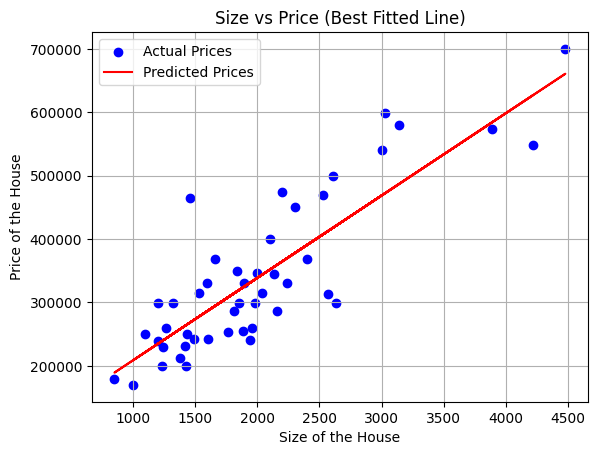

In [21]:
#Task 10
# Let us plot the actual prices and predicted prices
plt.scatter(df['Size'], df['Price'], color='blue', label='Actual Prices')

# Now calculate the predicted prices for the plot
predicted_prices_plot = theta[0] + theta[1] * (df['Size'] - df['Size'].mean()) / df['Size'].std()

# Finally pot the best-fitted line
plt.plot(df['Size'], predicted_prices_plot, color='red', label='Predicted Prices')
plt.title('Size vs Price (Best Fitted Line)')
plt.xlabel('Size of the House')
plt.ylabel('Price of the House')
plt.legend()
plt.grid()
plt.show()


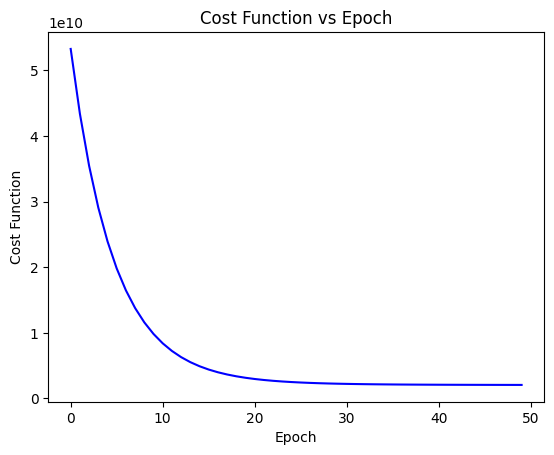

In [22]:
#Task 11
plt.plot(range(len(J_all)), J_all, color='blue')
plt.xlabel('Epoch')
plt.ylabel('Cost Function')
plt.title('Cost Function vs Epoch')
plt.show()

Intercept (theta_0): 89597.90954279754
Coefficients (theta_1, theta_2): 139.2106740176255, -8738.019112327831
Mean Squared Error: 4086560101.2056575
R² Score: 0.7329450180289142


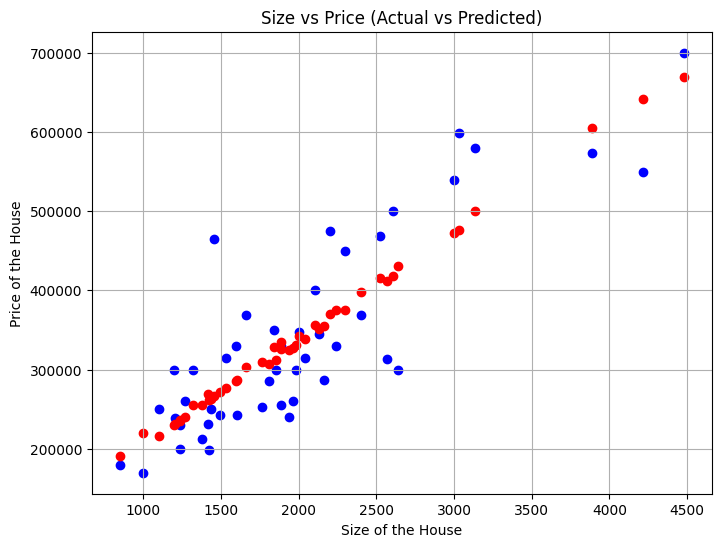

In [26]:
#Task 12

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
X = df[['Size', 'Bedroom']]
y = df['Price']

#We create and train the linear regression model
model = LinearRegression()
model.fit(X, y)

#Let us retrieve the intercept (theta_0) and coefficients (theta_1, theta_2)
theta_0 = model.intercept_
theta_1 = model.coef_[0]
theta_2 = model.coef_[1]

print(f"Intercept (theta_0): {theta_0}")
print(f"Coefficients (theta_1, theta_2): {theta_1}, {theta_2}")

#Let us predict the prices using the trained model
y_pred = model.predict(X)

# Now we should calculate Mean Squared Error (MSE) and R² score
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print(f"Mean Squared Error: {mse}")
print(f"R² Score: {r2}")

# Finally let us plot actual prices vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(df['Size'], y, color='blue', label='Actual Prices')
plt.scatter(df['Size'], y_pred, color='red', label='Predicted Prices')
plt.title('Size vs Price (Actual vs Predicted)')
plt.xlabel('Size of the House')
plt.ylabel('Price of the House')
plt.grid()
plt.show()

